# Figure SI: T-S Space Upper AM02

## Import Packages

In [1]:
import pandas as pd
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, zoomed_inset_axes
import matplotlib.ticker as mticker
from matplotlib import path
from matplotlib.colors import TwoSlopeNorm
import matplotlib.cm as cm
from matplotlib.patches import Polygon
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import matplotlib.lines as mlines
import matplotlib.patheffects as pe
import datetime
import math

import xarray as xr
from netCDF4 import Dataset
from xgcm import Grid
import cmaps
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os
import glob

import rioxarray

from dask.diagnostics import ProgressBar

from scipy.ndimage import gaussian_filter1d

from pyproj import Transformer

import seawater as sw
import gsw

import calendar

import pickle

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/sitecustomize.py:72: UserWarning: The seawater library is deprecated! Please use gsw instead.
  mod = _real_import(name, globals, locals, fromlist, level)


## Import Data

In [2]:
# ---------- OBSERVATIONAL DATA ----------
ROOT = '/g/data/gv90/ad6790/amery-amisor'
os.chdir(f'{ROOT}/notebooks')

from fun_filtering import lowpass_filter

df = pd.read_parquet(f'{ROOT}/data/proc/04_filtered.parquet')

# ---------- NEUTRAL DENSITY CURVES ----------
# Load in the neutral density contours as determined by Blanckensee et al. (2024)
with open("/g/data/gv90/ad6790/amery-amisor/data/external/SiennaNeve-CDObs-203a48c/Notebooks/neu_dens_contours.pkl", "rb") as f: 
    nd_contours = pickle.load(f)
x_curve1 = nd_contours["x_curve1"]  # 28.27 contour
y_curve1 = nd_contours["y_curve1"]
x_curve2 = nd_contours["x_curve2"]  # 28.00 contour
y_curve2 = nd_contours["y_curve2"]

## Define Resuable Functions

In [3]:
# Define a function to label the neutral density curves tangentially
def label_curve_tangent(ax, x_curve, y_curve, fraction, text, color, fontsize, **kwargs):
    n = len(x_curve)
    # Define an index for the anchor point based on the length of the curve and the fractional distance along it
    idx = int(fraction * (n - 1))
    # Define the anchor point
    anchor_point = (x_curve[idx], y_curve[idx])

    # Pick points neighbouring the anchoring point to estimate the tangent
    i0 = max(idx - 1, 0)
    i1 = min(idx + 1, n - 1)

    # Convert these points to display coordinates so the angle accounts of the axis scaling
    p0 = ax.transData.transform((x_curve[i0], y_curve[i0]))
    p1 = ax.transData.transform((x_curve[i1], y_curve[i1]))
    # Calculate the change in display in display coordinates in the x and y directions
    dx_display = p1[0] - p0[0] 
    dy_display = p1[1] - p0[1] 

    # Calculate the angle of the slope 
    angle = np.degrees(np.arctan2(dy_display, dx_display))
    
    # Find a perpendicular unit vector in display coordinates to create a buffer between the curve and the label 
    length = np.hypot(dx_display, dy_display)
    perp_x = -dy_display / length
    perp_y = dx_display / length

    # Find the anchor point and the offset point from here in display coordinates
    anchor_display = ax.transData.transform(anchor_point)
    offset_display = (anchor_display[0] + 10 * perp_x, anchor_display[1] + 10 * perp_y)

    # Convert this offset point back into data coordinates to be able to plot it correctly
    offset_point = ax.transData.inverted().transform(offset_display)

    # Check if the anchor point falls within the plot's visible area and if it doesn't we ignore this label
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    if not (xlim[0] <= anchor_point[0] <= xlim[1] and ylim[0] <= anchor_point[1] <= ylim[1]):
        return 

    ax.text(offset_point[0], offset_point[1], text, rotation=angle, rotation_mode="anchor", ha="center", va="center", color=color, fontsize=fontsize, **kwargs)

def _doy_month_ticks(doy_min, doy_max):
    """Return (tick_positions, tick_labels) for month starts within [doy_min, doy_max]."""
    ref = 2001  # non-leap reference year
    ticks, labels = [], []
    for m in range(1, 13):
        ts = pd.Timestamp(ref, m, 1)
        doy = ts.timetuple().tm_yday
        # In year-specific austral plots, December is shifted to negative DOY
        if doy_min < 0 and m == 12:
            doy -= 365
        if doy_min <= doy <= doy_max:
            ticks.append(doy)
            labels.append(ts.strftime("%b"))
    return ticks, labels

# trim a T-S curve so it starts on the 0 dbar freezing line rather than running below it
def clip_to_freezing(x, y):
    """Keep only the part of a T-S curve at or above the surface freezing point."""
    d = y - gsw.CT_freezing(x, 0, 0)
    keep = d >= 0
    if not keep.any():
        return x[keep], y[keep]
    i = np.argmax(keep)                       # first point above freezing
    if i == 0:
        return x[keep], y[keep]
    # Linear interpolation between the last point below and the first above, so the
    # curve begins exactly on the freezing line instead of jumping to the next sample
    f = -d[i-1] / (d[i] - d[i-1])
    x0 = x[i-1] + f * (x[i] - x[i-1])
    y0 = y[i-1] + f * (y[i] - y[i-1])
    return np.concatenate([[x0], x[keep]]), np.concatenate([[y0], y[keep]])


def truncate_cmap(cmap_name, lo=0.0, hi=1.0, n=256):
    """Keep only the lo-to-hi portion of a colormap (fractions of the full range)."""
    base = plt.get_cmap(cmap_name, n)
    return mcolors.ListedColormap(base(np.linspace(lo, hi, n)), name=f"{cmap_name}_trunc")

# Colormap for the DOY gradient plot — cyclic, maps naturally to a year
def roll_cyclic_cmap(cmap_name, shift, n=256):
    """Rotate a cyclic colormap by `shift` (fraction of a full cycle)."""
    base = plt.get_cmap(cmap_name, n)
    cols = base(np.linspace(0, 1, n))
    return mcolors.ListedColormap(np.roll(cols, int(round(shift * n)), axis=0), name=f"{cmap_name}_rolled")

## Define Constant and Common Variables

In [4]:
# Font sizes for this figure
FS_MAIN = 16      # axis labels, colourbar labels, water-mass labels
FS_SMALL = 14     # tick labels, legend, curve and contour labels

# Defaults for anything without its own fontsize (ticks, colourbar ticks, legend)
plt.rcParams.update({
    "font.size": FS_MAIN,
    "axes.titlesize": FS_MAIN,
    "axes.labelsize": FS_MAIN,
    "xtick.labelsize": FS_SMALL,
    "ytick.labelsize": FS_SMALL,
    "legend.fontsize": FS_SMALL,
})

In [5]:
# Define a dictionary mapping each MicroCAT to it's pre-calculated average pressure
# Average pressure is the mean pressure on deployment
AVG_PRESSURES = {
    "1969": 441.1,    "1970": 581.6,   "1971": 743.4,
    "1623": 338.5,    "1624": 562.7,   "1174": 770.2,
    "4055": 661.4,    "4054": 872.2,   "3883": 1227.1,
    "1972": 550.4,    "1973": 693.0,   "1974": 814.7,
    "7327": 580.5,    "7326": 738.8,   "7322": 876.6,
    "7325": 551.4,    "7324": 680.8,   "7323": 790.3,
}

# Colours assigned to boreholes in month mode (when multiple boreholes are shown)
BOREHOLE_COLOURS = {
    "AM01": {"1969": "darkgreen", "1970": "forestgreen", "1971": "lightgreen"},
    "AM02": {"1623": "darkred", "1624": "red", "1174": "lightcoral"},
    "AM03": {"4055": "saddlebrown", "4054": "sandybrown", "3883": "peachpuff"},
    "AM04": {"1972": "black", "1973": "grey", "1974": "lightgrey"},
    "AM05": {"7327": "indigo", "7326": "darkviolet", "7322": "violet"},
    "AM06": {"7325": "navy", "7324": "royalblue", "7323": "lightskyblue"}
}

POSITION_INDEX = {"upper": 0, "middle": 1, "lower": 2}

# Marker shapes cycling across cats in seasonal/doy modes
CAT_MARKERS = ["o", "s", "^", "D", "v", "P", "*"]

# Define a colourmap for the days-of-year
DOY_CMAP = roll_cyclic_cmap("twilight_shifted", 0.25)

# Define a colourmap for the water column of model data
# cmap = truncate_cmap('cmo.deep', 0.0, 0.85)
cmap = 'cmo.deep'

# Create a linear mapping of depth from 0 to 1 using the approximated shallowest and deepest levels (in metres) from across all borehole locations in the model 
norm = mcolors.Normalize(vmin=300, vmax=1300)

# Initialise a list of salinity values corresponding to the source water mass at ~-1.9C
# meltwater_mixing_lines = {'model': [34.64, 34.73], 'observational': [34.49, 34.68, 34.7]}
meltwater_mixing_lines = [34.67]

obsv_kw = dict(s=2)
freeze_kw = dict(color="blue", linestyle="-", lw=0.8, label="_", zorder=4)
isopycnal_kw = dict(colors="black", linestyles="-", linewidths=0.6, alpha=0.2, zorder=1)
neutral_kw = dict(color="r", linestyle="-", lw=1.5, zorder=4)
gade_kw = dict(color="k", linestyle="--", lw=1.5, label="_", zorder=5)
label_kw = dict(fontsize=FS_MAIN)
grid_labels=FS_SMALL
legend_kw = dict(ncol=2, fontsize=FS_SMALL, frameon=False, markerscale=2, fancybox=False)

## Figure 2
### Organise Data for Subplot a) All Datapoints in the Cavity (Pressure Coloured)

In [10]:
# Name of the pressure column in df
PRESSURE_COL = "pressure"

# Plot every Nth point. Set to 1 for all points, or raise it if the figure is slow to render or the saved file is unmanageably large
SUBSAMPLE = 1

if PRESSURE_COL not in df.columns:
    raise KeyError(f"'{PRESSURE_COL}' not in df. Available columns:\n{df.columns.tolist()}")

# Optional: keep only the three columns we need, drop any row missing one of them
obs = df[["absolute_salinity", "conservative_temperature", PRESSURE_COL]].dropna()

# Optional: sort deepest-first so that shallow points draw on top
# Without: whichever borehole is last is drawn on top
# obs = obs.sort_values(PRESSURE_COL, ascending=False)

# Axis limits
ylim_temp_p = (-2.4, -1.5)
xlim_sal_p = (34.201, 34.9)


if SUBSAMPLE > 1:
    obs = obs.iloc[::SUBSAMPLE]

print(f"{len(obs):,} observations plotted "
      f"(pressure {obs[PRESSURE_COL].min():.0f} to {obs[PRESSURE_COL].max():.0f} dbar)")

1,215,232 observations plotted (pressure 335 to 1228 dbar)


### Organise Data for Subplot b) All Supercooled Datapoints (DOY Coloured)

In [11]:
cats = [("AM02", "1623"), ("AM05", "7327"), ("AM04", "1972"), ("AM01", "1969")]

# Define if the composite data will determined using mean or median
average = "mean"

# Axis limits
ylim_temp_d = (-2.4, -1.7)
xlim_sal_d = (34.3, 34.8)

# Cats is a flat list of tuples, so just count it
multi_cat = len(cats) > 1

# First pass: collect data and DOY values for shared colormap normalisation
# Initialise an empty list to hold (borehole, cat, sub, doys) typle - one per successfully loaded instrument
cat_subsets = []
all_doys = []
all_cats, all_data = [], []

# Iterate over each borehole and cat
# Single loop unpacking each (borehole, cat) tuple
for borehole, cat in cats:
    # Create a mask to filter the dataframe for the specified borehole and cat
    mask = (df["borehole"] == borehole) & (df["cat"] == cat)
    sub = df[mask].copy()

    # Extract the position of the iterated MicroCAT in the water column at its respective borehole
    position = sub["water_column_position"].dropna().iloc[0]

    # Extract day of year and year from the time column
    sub["doy"] = sub["time"].dt.dayofyear + sub["time"].dt.hour / 24 + sub["time"].dt.minute / 1440

    # Round to nearest half-hour (1/48 of a day) since each MicroCAT records data with a half-hour interval, although due to time drift
    # the equivalent timestamp on different years may not be exactly the same time to the second
    sub["doy_bin"] = (sub["doy"] * 48).round() / 48

    # Plot the the median/mean
    # Create a mask for the year including the December the year before, and excluding the December of the same year
    agg = "mean" if average == "mean" else "median"
    # Calculate the median/mean temp and salinity values on the equivalent timestamp between different years
    sub = sub.groupby("doy_bin")[["conservative_temperature", "absolute_salinity"]].agg(agg).dropna()

    # Add a "month" to each binned DOY so we can assign it to a season
    # Use a non-leap reference year to convert DOY back to month
    sub["month"] = pd.to_datetime(sub.index, unit="D", origin="2001-01-01").month

    # Aggregating across years, indexed by DOY directly
    doys = sub.index.values

    cat_subsets.append((borehole, cat, sub, doys))

    # Add this iterated cats DOY values so we can compute a shared min/max
    all_doys.extend(doys)
    all_cats.append(cat)
    all_data.append(sub)

# Guard against all cats returning None
if not cat_subsets:
    raise ValueError("No data for any of the requested cats")

# Linear normaliser mapping DOY range -> [0,1]
# Renamed from norm, which the pressure plot uses for its own colour scale
doy_norm = mcolors.Normalize(vmin=min(all_doys), vmax=max(all_doys))

### Define Cluster Outlines

In [12]:
CLUSTER_OUTLINES = {
    "AM02": (
        np.array([34.5173, 34.5076, 34.4979, 34.4882, 34.4786, 34.4690, 34.4595, 34.4499, 34.4407, 34.4324, 34.4250, 34.4183, 34.4118, 34.4064, 34.4020, 34.3987, 34.3961, 34.3946, 34.3937, 34.3936, 34.3936, 34.3935, 34.3930, 34.3923, 34.3910, 34.3901, 34.3895, 34.3891, 34.3892, 34.3903, 34.3924, 34.3958, 34.3998, 34.4042, 34.4090, 34.4140, 34.4195, 34.4251, 34.4309, 34.4372, 34.4454, 34.4549, 34.4642, 34.4718, 34.4786, 34.4846, 34.4898, 34.4944, 34.4987, 34.5027, 34.5069, 34.5114, 34.5162, 34.5219, 34.5283, 34.5342, 34.5401, 34.5460, 34.5527, 34.5595, 34.5644, 34.5682, 34.5707, 34.5729, 34.5751, 34.5764, 34.5769, 34.5769, 34.5766, 34.5770, 34.5783, 34.5780, 34.5743, 34.5690, 34.5625, 34.5547, 34.5458, 34.5365, 34.5269, 34.5173]),
        np.array([-2.1681, -2.1681, -2.1674, -2.1657, -2.1638, -2.1612, -2.1587, -2.1567, -2.1523, -2.1452, -2.1364, -2.1266, -2.1165, -2.1051, -2.0930, -2.0802, -2.0671, -2.0537, -2.0401, -2.0265, -2.0129, -1.9993, -1.9857, -1.9721, -1.9586, -1.9451, -1.9315, -1.9179, -1.9043, -1.8908, -1.8775, -1.8648, -1.8524, -1.8403, -1.8284, -1.8167, -1.8055, -1.7944, -1.7834, -1.7730, -1.7662, -1.7639, -1.7675, -1.7758, -1.7855, -1.7962, -1.8077, -1.8197, -1.8319, -1.8444, -1.8566, -1.8687, -1.8805, -1.8915, -1.9017, -1.9125, -1.9234, -1.9341, -1.9441, -1.9538, -1.9654, -1.9780, -1.9911, -2.0044, -2.0176, -2.0311, -2.0447, -2.0583, -2.0719, -2.0855, -2.0990, -2.1125, -2.1251, -2.1364, -2.1465, -2.1546, -2.1600, -2.1637, -2.1663, -2.1681]),
    ),
    "AM01": (
        np.array([34.5764, 34.5820, 34.5879, 34.5946, 34.6018, 34.6099, 34.6189, 34.6267, 34.6334, 34.6394, 34.6453, 34.6514, 34.6582, 34.6665, 34.6762, 34.6878, 34.7001, 34.7078, 34.7094, 34.7041, 34.6963, 34.6884, 34.6828, 34.6793, 34.6755, 34.6711, 34.6657, 34.6585, 34.6497, 34.6416, 34.6357, 34.6322, 34.6330, 34.6394, 34.6504, 34.6632, 34.6763, 34.6893, 34.7024, 34.7154, 34.7285, 34.7415, 34.7545, 34.7671, 34.7775, 34.7841, 34.7807, 34.7704, 34.7580, 34.7450, 34.7319, 34.7188, 34.7057, 34.6928, 34.6797, 34.6666, 34.6535, 34.6405, 34.6274, 34.6143, 34.6013, 34.5882, 34.5751, 34.5621, 34.5494, 34.5371, 34.5250, 34.5133, 34.5024, 34.4925, 34.4882, 34.4961, 34.5082, 34.5212, 34.5341, 34.5463, 34.5556, 34.5630, 34.5699, 34.5764]),
        np.array([-2.1192, -2.1026, -2.0863, -2.0705, -2.0552, -2.0409, -2.0276, -2.0129, -1.9971, -1.9809, -1.9645, -1.9483, -1.9326, -1.9185, -1.9063, -1.8989, -1.9038, -1.9184, -1.9363, -1.9528, -1.9675, -1.9820, -1.9984, -2.0161, -2.0337, -2.0509, -2.0675, -2.0828, -2.0962, -2.1106, -2.1270, -2.1445, -2.1627, -2.1782, -2.1875, -2.1911, -2.1926, -2.1940, -2.1952, -2.1962, -2.1977, -2.1991, -2.2013, -2.2060, -2.2168, -2.2323, -2.2490, -2.2599, -2.2652, -2.2669, -2.2668, -2.2664, -2.2677, -2.2700, -2.2709, -2.2713, -2.2713, -2.2713, -2.2721, -2.2731, -2.2741, -2.2747, -2.2744, -2.2731, -2.2686, -2.2626, -2.2555, -2.2474, -2.2371, -2.2253, -2.2091, -2.1951, -2.1886, -2.1867, -2.1840, -2.1783, -2.1657, -2.1507, -2.1351, -2.1192]),
    ),
    "AM04": (
        np.array([34.5946, 34.5982, 34.5966, 34.5927, 34.5883, 34.5835, 34.5787, 34.5740, 34.5692, 34.5646, 34.5607, 34.5572, 34.5536, 34.5501, 34.5460, 34.5414, 34.5369, 34.5327, 34.5286, 34.5246, 34.5209, 34.5171, 34.5134, 34.5100, 34.5063, 34.5024, 34.4982, 34.4936, 34.4890, 34.4843, 34.4796, 34.4749, 34.4701, 34.4653, 34.4606, 34.4559, 34.4514, 34.4469, 34.4427, 34.4396, 34.4386, 34.4389, 34.4389, 34.4389, 34.4389, 34.4398, 34.4414, 34.4440, 34.4478, 34.4521, 34.4566, 34.4612, 34.4659, 34.4706, 34.4753, 34.4800, 34.4848, 34.4896, 34.4944, 34.4991, 34.5039, 34.5087, 34.5135, 34.5182, 34.5230, 34.5278, 34.5326, 34.5373, 34.5421, 34.5469, 34.5516, 34.5564, 34.5612, 34.5660, 34.5707, 34.5755, 34.5803, 34.5851, 34.5898, 34.5946]),
        np.array([-2.3173, -2.3135, -2.3077, -2.3040, -2.3018, -2.3018, -2.3018, -2.3012, -2.3007, -2.2995, -2.2956, -2.2912, -2.2867, -2.2822, -2.2789, -2.2770, -2.2748, -2.2717, -2.2683, -2.2646, -2.2605, -2.2564, -2.2523, -2.2475, -2.2433, -2.2396, -2.2364, -2.2346, -2.2333, -2.2321, -2.2314, -2.2305, -2.2304, -2.2304, -2.2315, -2.2324, -2.2344, -2.2368, -2.2398, -2.2449, -2.2514, -2.2580, -2.2647, -2.2714, -2.2781, -2.2847, -2.2909, -2.2965, -2.3004, -2.3033, -2.3056, -2.3071, -2.3085, -2.3095, -2.3101, -2.3108, -2.3110, -2.3113, -2.3116, -2.3118, -2.3121, -2.3124, -2.3127, -2.3129, -2.3132, -2.3135, -2.3137, -2.3140, -2.3143, -2.3146, -2.3148, -2.3151, -2.3154, -2.3156, -2.3159, -2.3162, -2.3165, -2.3167, -2.3170, -2.3173]),
    ),
    "AM05": (
        np.array([34.5463, 34.5383, 34.5302, 34.5222, 34.5142, 34.5061, 34.4981, 34.4902, 34.4824, 34.4746, 34.4668, 34.4592, 34.4519, 34.4449, 34.4376, 34.4304, 34.4231, 34.4155, 34.4077, 34.4016, 34.4070, 34.4149, 34.4229, 34.4310, 34.4390, 34.4471, 34.4551, 34.4631, 34.4712, 34.4792, 34.4873, 34.4953, 34.5033, 34.5114, 34.5194, 34.5274, 34.5354, 34.5434, 34.5515, 34.5595, 34.5675, 34.5755, 34.5836, 34.5916, 34.5997, 34.6077, 34.6158, 34.6238, 34.6319, 34.6399, 34.6480, 34.6560, 34.6640, 34.6720, 34.6800, 34.6877, 34.6952, 34.7022, 34.7068, 34.7055, 34.6982, 34.6904, 34.6824, 34.6743, 34.6663, 34.6582, 34.6502, 34.6422, 34.6341, 34.6261, 34.6180, 34.6100, 34.6019, 34.5939, 34.5859, 34.5780, 34.5701, 34.5622, 34.5543, 34.5463]),
        np.array([-2.3734, -2.3734, -2.3734, -2.3729, -2.3724, -2.3713, -2.3701, -2.3682, -2.3658, -2.3629, -2.3598, -2.3561, -2.3514, -2.3460, -2.3412, -2.3360, -2.3314, -2.3279, -2.3254, -2.3188, -2.3117, -2.3098, -2.3087, -2.3092, -2.3093, -2.3098, -2.3104, -2.3106, -2.3109, -2.3115, -2.3115, -2.3122, -2.3126, -2.3136, -2.3143, -2.3151, -2.3141, -2.3137, -2.3143, -2.3152, -2.3160, -2.3169, -2.3175, -2.3175, -2.3175, -2.3175, -2.3175, -2.3178, -2.3181, -2.3183, -2.3187, -2.3194, -2.3203, -2.3211, -2.3227, -2.3260, -2.3299, -2.3353, -2.3441, -2.3546, -2.3592, -2.3616, -2.3629, -2.3629, -2.3629, -2.3627, -2.3624, -2.3618, -2.3613, -2.3613, -2.3613, -2.3613, -2.3617, -2.3625, -2.3639, -2.3657, -2.3681, -2.3699, -2.3720, -2.3734]),
    ),
}

OUTLINE_LABELS = {"AM02": (34.362, -1.971), "AM01": (34.692, -2.083), "AM04": (34.412, -2.255), "AM05": (34.718, -2.375)}

### PLOT

Reference Pressure for Plot a): 693.0388888888888
Reference Pressure for Plot b): 477.625


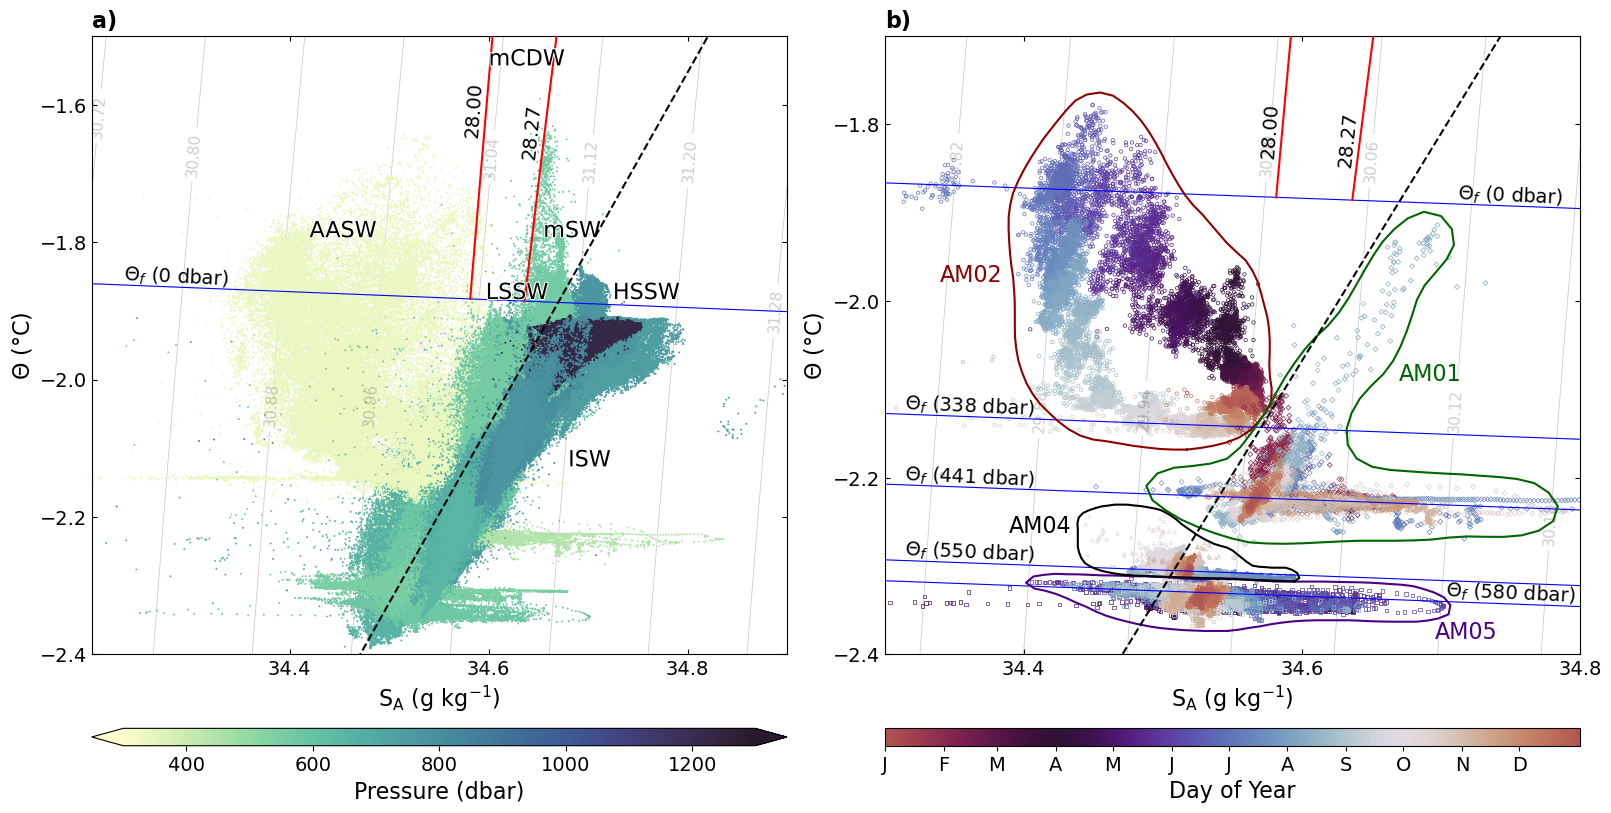

In [13]:
# One figure with the two plots side by side, each with its own axis limits
fig, (ax_p, ax_d) = plt.subplots(1, 2, figsize=(16, 8), layout='constrained')

# Each plot gets its own limits
ax_p.set_xlim(*xlim_sal_p)
ax_p.set_ylim(*ylim_temp_p)
ax_d.set_xlim(*xlim_sal_d)
ax_d.set_ylim(*ylim_temp_d)

# Tick spacing on each plot
ax_p.xaxis.set_major_locator(mticker.MultipleLocator(0.2))
ax_p.yaxis.set_major_locator(mticker.MultipleLocator(0.2))
ax_d.xaxis.set_major_locator(mticker.MultipleLocator(0.2))
ax_d.yaxis.set_major_locator(mticker.MultipleLocator(0.2))

for ax in (ax_p, ax_d):
    ax.tick_params(axis="both", which="both", direction="in", top=True, right=True)

# ---------- LEFT: COLOURED BY PRESSURE ---------- 
# Plot all recorded observational datapoints
# rasterized=True keeps the point cloud as an embedded image rather than a million individual vector circles - essential for a usable file size
sc_p = ax_p.scatter(obs["absolute_salinity"], obs["conservative_temperature"], c=obs[PRESSURE_COL], cmap=cmap, norm=norm, s=2, edgecolors='none', zorder=3, rasterized=True)

# ---------- RIGHT: COLOURED BY DAY OF YEAR ----------
sc_d = None

# Second pass: scatter each cat with shared normalisation
# Iterate over each tuple in the collected data representative of each cat
handles = []
for j, (borehole, cat, sub, doys) in enumerate(cat_subsets):
    # Allocate a unique marker (up to 7) for each different cat
    marker = CAT_MARKERS[j % len(CAT_MARKERS)]
    # Plot every observation for this iterated cat, mapping each DOY value with the linear normaliser and the chosen colour map
    # sc = ax.scatter(sub["absolute_salinity"], sub["conservative_temperature"], c=doys, cmap=DOY_CMAP, norm=norm, marker=marker, s=6, zorder=3)
    sc_d = ax_d.scatter(sub["absolute_salinity"], sub["conservative_temperature"], facecolors='none', edgecolors=plt.get_cmap(DOY_CMAP)(doy_norm(doys)), marker=marker, s=6, linewidths=0.5, zorder=3)
    if multi_cat:
        handles.append(mlines.Line2D([], [], marker=CAT_MARKERS[j % len(CAT_MARKERS)], color="grey", linestyle="None", markersize=6, label=f"({borehole}-{AVG_PRESSURES[cat]:.0f} dbar)"))

# ---------- COMMON OVERLAYS ---------- 
for ax in (ax_p, ax_d):
    # Define the range of temp and salinity over which to plot overlays
    salinity_range = np.linspace(*ax.get_xlim(), 100)
    temp_range = np.linspace(*ax.get_ylim(), 100)

    # - Freezing point temperature line at 0 dbar (saturation fraction = 0) -
    CT_freeze_0 = gsw.CT_freezing(salinity_range, 0, 0)
    ax.plot(salinity_range, CT_freeze_0, **freeze_kw)
    label_curve_tangent(ax, salinity_range, CT_freeze_0, 0.9 if ax is ax_d else 0.125, r"$\Theta_f$ (0 dbar)", "black", grid_labels, zorder=3)

    # - Neutral density curves from Blanckensee et al. (2024) -
    xc1, yc1 = clip_to_freezing(np.asarray(x_curve1), np.asarray(y_curve1))
    xc2, yc2 = clip_to_freezing(np.asarray(x_curve2), np.asarray(y_curve2))
    ax.plot(xc1, yc1, **neutral_kw)
    ax.plot(xc2, yc2, **neutral_kw)

    # - Meltwater mixing line using gsw (equation 16 from McDougall et al. (2014)) -
    # First, assume "the temperature of the glacial ice,215 C, measured from a thermistor cable at AM01" as per Herraiz-Borreguero et al. (2013) (also used in Silvano et al. (2017))
    t_ice = -15.0

    # REVIEW - WHAT PRESSURE DO WE WANT TO PUT HERE?? (note: slope is not particularly sensitive to this pressure)
    pressure_source = 550

    for salinity_source in meltwater_mixing_lines:
        # Here, we will define the temp of the source water mass as the surface (0 dbar) freezing point temperature at the given source salinities we have chosen
        temp_source = float(gsw.CT_freezing(salinity_source, 0, 0))
        dSA_dCT = gsw.ice.melting_ice_SA_CT_ratio(salinity_source, temp_source, pressure_source, t_ice)
        slope = 1 / dSA_dCT  # dCT/dSA
        CT_gade = temp_source + slope * (salinity_range - salinity_source)
        ax.plot(salinity_range, CT_gade, **gade_kw)

# Neutral density labels set per plot
label_curve_tangent(ax_p, xc2, yc2, 0.062, "28.00", "black", grid_labels)
label_curve_tangent(ax_p, xc1, yc1, 0.08, "28.27", "black", grid_labels)
label_curve_tangent(ax_d, xc2, yc2, 0.03, "28.00", "black", grid_labels)
label_curve_tangent(ax_d, xc1, yc1, 0.03, "28.27", "black", grid_labels)

# ---------- OVERLAYS FOR THE PRESSURE PLOT ONLY ----------
# Define the range of temp and salinity over which to plot overlays
salinity_range = np.linspace(*ax_p.get_xlim(), 100)
temp_range = np.linspace(*ax_p.get_ylim(), 100)

# - Isopycnals (potential density anomaly contours) referenced to the average pressure of ALL MicroCATs
# Reference pressure for the potential density anomaly (dbar)
pressures = []
for pressure in AVG_PRESSURES.values():
    pressures.append(pressure)
reference_pressure = np.mean(pressures)
print(f"Reference Pressure for Plot a): {reference_pressure}")
    
salinity_grid, temp_grid = np.meshgrid(salinity_range, temp_range)
sigma = gsw.rho(salinity_grid, temp_grid, reference_pressure) - 1000
cs = ax_p.contour(salinity_grid, temp_grid, sigma, **isopycnal_kw)
ax_p.clabel(cs, inline=True, fontsize=11, fmt="%.2f")

# - High Salinity Shelf Water -
# Define after Herraiz-Borreguero et al. (2015) and Rosevear et al. (2022) - -1.95 <= Theta <= -1.85 and S_A > 34.67 g/kg
hssw_temp = (-1.95, -1.85)
hssw_sal_min = 34.67
# ax_p.plot([hssw_sal_min, xlim_sal_p[1]], [hssw_temp[0], hssw_temp[0]], color="black", linestyle="-", lw=1.5, label="_", zorder=4)
# ax_p.plot([hssw_sal_min, xlim_sal_p[1]], [hssw_temp[1], hssw_temp[1]], color="black", linestyle="-", lw=1.5, label="_", zorder=4)
# ax_p.plot([hssw_sal_min, hssw_sal_min], [hssw_temp[0], hssw_temp[1]], color="black", linestyle="-", lw=1.5, label="_", zorder=4)
ax_p.text(34.725, -1.89, "HSSW", color="black", va="bottom", ha="left", zorder=4, path_effects=[pe.withStroke(linewidth=1.5, foreground='white')], **label_kw)

# - Low Salinity Shelf Water -
# -1.95 <= Theta <= -1.85 and S_A < 34.67 g/kg
lssw_temp = (-1.95, -1.85)
lssw_sal_max = 34.67
# ax_p.plot([xlim_sal_p[0], lssw_sal_max], [lssw_temp[0], lssw_temp[0]], color="black", linestyle="-", lw=1.5, label="_", zorder=4)
# ax_p.plot([xlim_sal_p[0], lssw_sal_max], [lssw_temp[1], lssw_temp[1]], color="black", linestyle="-", lw=1.5, label="_", zorder=4)
ax_p.text(34.66, -1.89, "LSSW", color="black", va="bottom", ha="right", zorder=4, path_effects=[pe.withStroke(linewidth=1.5, foreground='white')], **label_kw)

# - Antarctic Surface Water -
ax_p.text(34.42, -1.8, "AASW", color="black", va="bottom", ha="left", zorder=4, path_effects=[pe.withStroke(linewidth=1.5, foreground='white')], **label_kw)

# - modified Circumpolar Deep Water -
ax_p.text(34.6, -1.55, "mCDW", color="black", va="bottom", ha="left", zorder=4, path_effects=[pe.withStroke(linewidth=1.5, foreground='white')], **label_kw)

# - Ice Shelf Water -
ax_p.text(34.68, -2.1, "ISW", color="black", va="top", ha="left", zorder=4, path_effects=[pe.withStroke(linewidth=1.5, foreground='white')], **label_kw)

# - modified Shelf Water -
ax_p.text(34.655, -1.8, "mSW", color="black", va="bottom", ha="left", zorder=4, path_effects=[pe.withStroke(linewidth=1.5, foreground='white')], **label_kw)

# ---------- OVERLAYS FOR THE DOY PLOT ONLY ----------
salinity_range = np.linspace(*ax_d.get_xlim(), 100)
temp_range = np.linspace(*ax_d.get_ylim(), 100)

# - Isopycnals (potential density anomaly contours) referenced to the average pressure of all plotted MicroCATs
# Reference pressure for the potential density anomaly (dbar)
pressures = []
for borehole, cat in cats:
    pressures.append(AVG_PRESSURES[cat])
reference_pressure = np.mean(pressures)
print(f"Reference Pressure for Plot b): {reference_pressure}")
    
salinity_grid, temp_grid = np.meshgrid(salinity_range, temp_range)
sigma = gsw.rho(salinity_grid, temp_grid, reference_pressure) - 1000
cs = ax_d.contour(salinity_grid, temp_grid, sigma, **isopycnal_kw)
ax_d.clabel(cs, inline=True, fontsize=11, fmt="%.2f")

# - Freezing point temperature line at the average mooring pressure (determined at deployment) -
for borehole, cat in cats:
    pressure_ice_base = AVG_PRESSURES[cat]
    # Use the gsw package to calculate the freezing point temp across the plotted salinity range
    CT_freeze_p = gsw.CT_freezing(salinity_range, pressure_ice_base, 0)
    ax_d.plot(salinity_range, CT_freeze_p, **freeze_kw)
    label_position = 0.9 if cat == "7327" else 0.125
    label_curve_tangent(ax_d, salinity_range, CT_freeze_p, label_position, fr"$\Theta_f$ ({pressure_ice_base:.0f} dbar)", "black", grid_labels, zorder=3)

for borehole, cat in cats:
    for name, (S, T) in CLUSTER_OUTLINES.items():
        if name == borehole:
            ax_d.plot(S, T, color=BOREHOLE_COLOURS[borehole][cat], lw=1.5, zorder=4)
            ax_d.text(*OUTLINE_LABELS[name], borehole, color=BOREHOLE_COLOURS[borehole][cat], ha="center", va="center", zorder=4, **label_kw)

# ---------- PRESSURE COLOURBAR ----------
# Add the colourbar to the figure
cbar = fig.colorbar(sc_p, ax=ax_p, location='bottom', pad=0.02, aspect=40, extend='both')
# Lable the colourbar axis
cbar.set_label("Pressure (dbar)", **label_kw)
# Tick every 100 dbar
cbar.ax.xaxis.set_major_locator(mticker.MultipleLocator(200))

# ---------- DOY COLOURBAR ----------
# Draw the colourbar labelled with calender months
# Only draw the colourbar is at least one scatter was drawn
sm = cm.ScalarMappable(norm=doy_norm, cmap=DOY_CMAP) 
# Add the colourbar to the figure
cbar_d = fig.colorbar(sm, ax=ax_d, location='bottom', pad=0.02, aspect=40)
# Lable the colourbar axis
cbar_d.set_label("Day of Year")
# Call the helper function to find which month start DOYs fall in the data's range, returning positions and abbreviated names
ticks, tick_labels = _doy_month_ticks(min(all_doys), max(all_doys))
# Every second month only - [::3] for every third
cbar_d.set_ticks(ticks[::1])
cbar_d.set_ticklabels([label[0] for label in tick_labels[::1]])

# Produce a legend for the markers defining different cats, if there is more than one cat
# if multi_cat:
#     ax_d.legend(handles=handles, loc="best")

ax_p.set_title('a)', loc='left', fontweight="bold")
ax_d.set_title('b)', loc='left', fontweight="bold")

# Both axis labels on both plots
for ax in (ax_p, ax_d):
    ax.set_xlabel(r"$\mathrm{S_{A} \ (g \ kg^{-1})}$", **label_kw)
    ax.set_ylabel(r"$\Theta$ (°C)", **label_kw)

fig.savefig('/g/data/gv90/ad6790/amery-amisor/notebooks/figures/ObsT-SAll.jpg', format='jpg', dpi=600)
plt.show()